# Liveability exploration

Explore amenity access for Greater Melbourne rental listings: load cleaned properties with amenity distances, map mean nearest-amenity distance by SA2, compare amenity access against distance to the CBD, and compare mean rent per bedroom against distance to the CBD.

## Setup

In [115]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LogNorm
from matplotlib.ticker import FuncFormatter
from shapely.geometry import Point
import statsmodels.api as sm

ROOT = Path("../..")
DATA = ROOT / "data"

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)

# Nice km ticks for log-scaled distance axes / colourbars
KM_TICK_CANDIDATES = np.array(
    [0.05, 0.1, 0.15, 0.2, 0.3, 0.5, 0.7, 1, 1.5, 2, 3, 4, 5, 7, 10, 15, 20, 30, 50]
)


def km_ticks(vmin, vmax):
    return KM_TICK_CANDIDATES[(KM_TICK_CANDIDATES >= vmin) & (KM_TICK_CANDIDATES <= vmax)]

## Data

### Load properties + amenities

- `cleaned_properties.csv` — scraped rent.com.au listings after cleaning
- `listings_with_amenity_distances.csv` — nearest-amenity distances and counts (schools, parks, transit, supermarkets)

Joined on `latitude` / `longitude` (amenity features are unique per location).

In [116]:
listings = pd.read_csv(DATA / "preprocessed_data" / "cleaned_properties.csv")
listings["suburb"] = listings["suburb"].str.strip().str.lower()

amenities = pd.read_csv(DATA / "amenity_data" / "listings_with_amenity_distances.csv")

amenity_cols = [
    "nearest_school_km",
    "school_count_2km",
    "nearest_train_station_km",
    "nearest_park_km",
    "park_count_2km",
    "nearest_supermarket_km",
    "supermarket_count_4km",
    "nearest_tram_stop_km",
    "tram_stop_capped",
    "nearest_bus_stop_km",
    "bus_stop_capped",
]

# Amenity features are identical for a given lat/lon; drop duplicates so the merge stays 1:1
amenities = amenities.drop_duplicates(subset=["latitude", "longitude"])[
    ["latitude", "longitude"] + amenity_cols
]

df = listings.merge(amenities, on=["latitude", "longitude"], how="left")

print(f"listings: {len(listings):,} | amenities (unique locs): {len(amenities):,} | merged: {len(df):,}")
print(f"amenity match rate: {df[amenity_cols[0]].notna().mean():.1%}")
df.head()

listings: 9,232 | amenities (unique locs): 8,090 | merged: 9,232
amenity match rate: 100.0%


,latitude,longitude,street_address,suburb,postcode,weekly_rent_number,property_type,bedrooms,bathrooms,ensuites,car_spaces,furnished,partially_furnished,pets_allowed,long_term_lease,is_build_to_rent,transit_score,walk_score,airconditioning_air-conditioning,airconditioning_ducted,...,services_available_pay_tv,services_available_solar_power,services_available_water,services_heating,spa_outside,spa_spa,sport_gym,sport_pool,sport_tennis_court,nearest_school_km,school_count_2km,nearest_train_station_km,nearest_park_km,park_count_2km,nearest_supermarket_km,supermarket_count_4km,nearest_tram_stop_km,tram_stop_capped,nearest_bus_stop_km,bus_stop_capped
0,-37.814688,144.941083,"1007/20 Rakaia Way,",docklands,3008,730.0,Apartment,2,1,0.0,1,0,0,0.0,0,0,100,92.0,0,0,...,0,0,0,0,0,0,0,0,0,0.2239,4,1.7541,0.3272,27,0.2927,47,0.2090,False,0.4570,False
1,-37.813699,144.953926,"4408/601 Little Lonsdale Street,",cbd,3000,670.0,Apartment,2,1,0.0,1,0,0,0.0,0,0,100,99.0,0,0,...,0,0,0,0,0,0,1,0,0,0.2451,7,0.5049,0.1751,42,0.5418,50,0.1963,False,0.1793,False
2,-37.930804,145.112401,"29 Bond Street,",clayton south,3169,615.0,House,3,1,0.0,3,0,0,0.0,0,0,45,76.0,0,0,...,0,0,0,0,0,0,0,0,0,0.8481,4,1.5133,0.4956,32,0.8235,13,3.0000,True,0.2838,False
3,-37.869108,144.990422,"108/126 Chapel Street,",st kilda,3182,540.0,Apartment,1,1,0.0,1,0,0,0.0,0,0,80,98.0,0,0,...,0,0,0,0,0,0,0,0,0,0.6413,11,0.2585,0.4311,35,0.2379,24,0.0904,False,0.3271,False
4,-37.923180,145.128629,"33/2 Greenfield Drive,",clayton,3168,550.0,Apartment,2,1,0.0,1,0,0,0.0,0,0,65,58.0,0,0,...,0,0,0,0,0,0,0,0,0,0.8972,3,1.1356,0.7598,17,1.0678,12,3.0000,True,0.7769,False


### Aggregate listings to SA2

Choose an amenity column, join listings into Greater Melbourne SA2s, and compute:

1. Mean nearest-amenity distance per SA2
2. Straight-line distance from each SA2 centroid to the CBD (Melbourne GPO)

Only SA2s with at least `MIN_N` listings are kept (applied upstream so amenity, rent, and tradeoff analyses share the same sample).

In [117]:
# Switch amenity here — one of:
#   nearest_school_km, nearest_train_station_km, nearest_park_km,
#   nearest_supermarket_km, nearest_tram_stop_km, nearest_bus_stop_km
AMENITY = "nearest_school_km"
MIN_N = 5  # drop SA2s with fewer listings (noise / one-off extremes)

# Melbourne GPO (approx. CBD reference point)
CBD_LAT, CBD_LON = -37.8136, 144.9631

zones = gpd.read_file(DATA / "geospatial_data" / "Vic_Area_Zones" / "Vic_Area_Zones.shp")
zones = zones[zones["GCC_NAME21"] == "Greater Melbourne"].copy()

# Project to metres for true straight-line distances (GDA2020 / MGA zone 55)
zones_m = zones.to_crs(epsg=7855)
cbd = (
    gpd.GeoSeries([Point(CBD_LON, CBD_LAT)], crs="EPSG:4326")
    .to_crs(zones_m.crs)
    .iloc[0]
)
zones_m["dist_cbd_km"] = zones_m.geometry.centroid.distance(cbd) / 1000.0

clean = df.dropna(subset=["latitude", "longitude", AMENITY]).copy()
points = gpd.GeoDataFrame(
    clean,
    geometry=gpd.points_from_xy(clean["longitude"], clean["latitude"]),
    crs="EPSG:4326",
).to_crs(zones.crs)

joined = gpd.sjoin(points, zones[["SA2_NAME21", "geometry"]], how="inner", predicate="within")

n_by_sa2 = joined.groupby("SA2_NAME21").size()
eligible_sa2s = n_by_sa2[n_by_sa2 >= MIN_N].index
n_dropped = int((n_by_sa2 < MIN_N).sum())
joined = joined[joined["SA2_NAME21"].isin(eligible_sa2s)].copy()

avg_by_sa2 = (
    joined.groupby("SA2_NAME21")
    .agg(avg_amenity_km=(AMENITY, "mean"), n_listings=("SA2_NAME21", "size"))
    .reset_index()
)

sa2 = (
    zones_m[["SA2_NAME21", "geometry", "dist_cbd_km"]]
    .merge(avg_by_sa2, on="SA2_NAME21", how="inner")
)

print(f"AMENITY = {AMENITY} | MIN_N = {MIN_N}")
print(f"Dropped {n_dropped} SA2s with < {MIN_N} listings")
print(f"SA2s retained: {len(sa2):,} / {len(zones_m):,} Greater Melbourne SA2s")
sa2[["SA2_NAME21", "dist_cbd_km", "avg_amenity_km", "n_listings"]].sort_values("dist_cbd_km").head()

AMENITY = nearest_school_km | MIN_N = 5
Dropped 45 SA2s with < 5 listings
SA2s retained: 298 / 361 Greater Melbourne SA2s


,SA2_NAME21,dist_cbd_km,avg_amenity_km,n_listings
21,Melbourne CBD - East,0.492020,0.604344,103
23,Melbourne CBD - West,0.520396,0.594187,226
22,Melbourne CBD - North,0.526832,0.814523,189
27,West Melbourne - Residential,1.299765,0.637317,47
25,Southbank (West) - South Wharf,1.320555,1.043053,95


## Mean amenity distance by SA2

Choropleth of mean nearest-amenity distance across Greater Melbourne SA2s (log colour scale). Change `AMENITY` in the aggregation cell above and re-run from there.

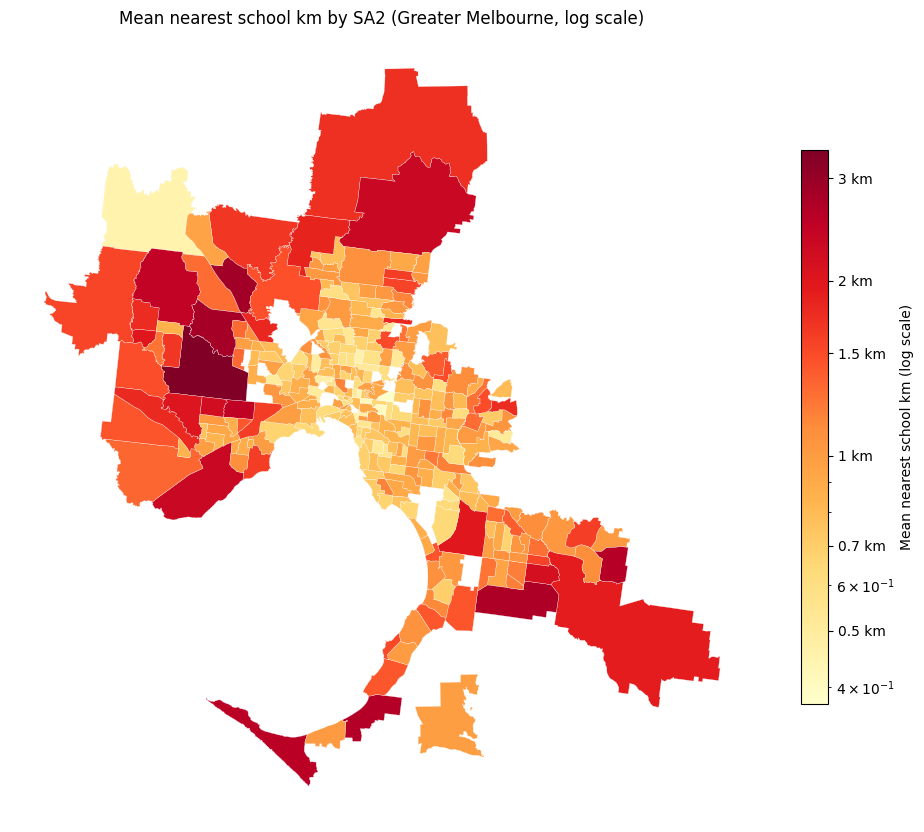

In [118]:
plot_data = sa2[sa2["avg_amenity_km"] > 0]
vmin, vmax = plot_data["avg_amenity_km"].min(), plot_data["avg_amenity_km"].max()
norm = LogNorm(vmin=vmin, vmax=vmax)

fig, ax = plt.subplots(figsize=(12, 12))
sa2.plot(ax=ax, color="#f0f0f0", edgecolor="white", linewidth=0.3)
plot_data.plot(
    column="avg_amenity_km",
    cmap="YlOrRd",
    norm=norm,
    legend=False,
    edgecolor="white",
    linewidth=0.2,
    ax=ax,
)

mappable = ScalarMappable(norm=norm, cmap="YlOrRd")
cbar = fig.colorbar(mappable, ax=ax, shrink=0.6)
cbar.set_ticks(km_ticks(vmin, vmax))
cbar.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g} km"))
cbar.set_label(f"Mean {AMENITY.replace('_', ' ')} (log scale)")

ax.set_title(f"Mean {AMENITY.replace('_', ' ')} by SA2 (Greater Melbourne, log scale)")
ax.set_axis_off()
plt.show()

## Amenity access vs distance to CBD

Each point is one SA2: straight-line centroid→CBD distance vs mean nearest-amenity distance for listings in that SA2.

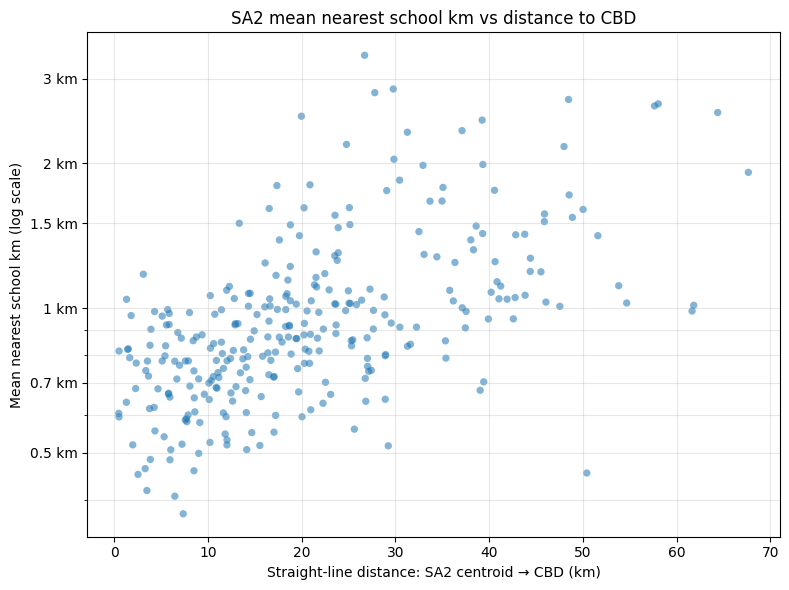

In [119]:
plot_sa2 = sa2[sa2["avg_amenity_km"] > 0]
plot_sa2[["SA2_NAME21", "dist_cbd_km", "avg_amenity_km"]].to_csv("transformed_data/amenity_access_vs_distance_to_cbd.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(
    plot_sa2["dist_cbd_km"],
    plot_sa2["avg_amenity_km"],
    alpha=0.55,
    s=28,
    edgecolor="none",
)
ax.set_yscale("log")

vmin, vmax = plot_sa2["avg_amenity_km"].min(), plot_sa2["avg_amenity_km"].max()
ax.set_yticks(km_ticks(vmin, vmax))
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g} km"))

ax.set_xlabel("Straight-line distance: SA2 centroid → CBD (km)")
ax.set_ylabel(f"Mean {AMENITY.replace('_', ' ')} (log scale)")
ax.set_title(f"SA2 mean {AMENITY.replace('_', ' ')} vs distance to CBD")
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

### Fitting a model

Log-linear regression of mean amenity distance on CBD distance. Predictions are back-transformed from the log scale; `true_pct_above_mean` is how far the observed amenity distance sits above/below the predicted value for that SA2's CBD distance.

In [120]:
fit_df = plot_sa2[["SA2_NAME21", "dist_cbd_km", "avg_amenity_km"]].dropna().copy()
X = sm.add_constant(fit_df["dist_cbd_km"])
y = np.log(fit_df["avg_amenity_km"])

amenity_fit = sm.OLS(y, X).fit()
print(amenity_fit.summary())

                            OLS Regression Results                            
Dep. Variable:         avg_amenity_km   R-squared:                       0.332
Model:                            OLS   Adj. R-squared:                  0.330
Method:                 Least Squares   F-statistic:                     147.2
Date:                Mon, 05 Oct 2026   Prob (F-statistic):           9.17e-28
Time:                        22:00:56   Log-Likelihood:                -80.942
No. Observations:                 298   AIC:                             165.9
Df Residuals:                     296   BIC:                             173.3
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          -0.4135      0.033    -12.361      

In [121]:
fit_df["predicted_amenity_dist"] = np.exp(amenity_fit.predict(X))
fit_df["true_pct_above_mean"] = (
    (fit_df["avg_amenity_km"] - fit_df["predicted_amenity_dist"])
    / fit_df["predicted_amenity_dist"]
)

fit_df.head()

,SA2_NAME21,dist_cbd_km,avg_amenity_km,predicted_amenity_dist,true_pct_above_mean
0,Brunswick East,5.125791,0.776594,0.718408,0.080993
1,Brunswick West,5.868449,0.924552,0.727077,0.271602
2,Pascoe Vale South,8.084715,0.688650,0.753573,-0.086153
3,Brunswick - North,5.880801,0.974691,0.727222,0.340294
4,Brunswick - South,4.676849,0.679652,0.713218,-0.047063


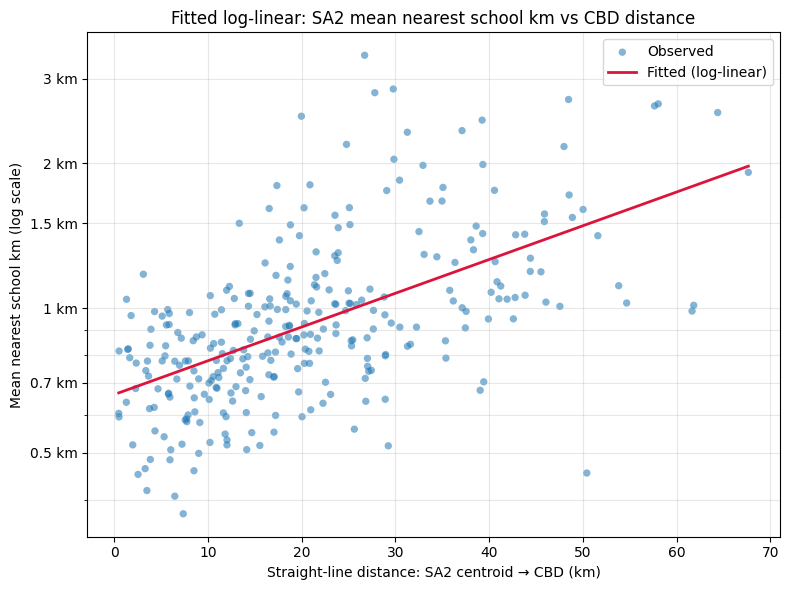

In [122]:
x_line = np.linspace(fit_df["dist_cbd_km"].min(), fit_df["dist_cbd_km"].max(), 200)
y_line = np.exp(amenity_fit.predict(sm.add_constant(x_line)))

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(
    fit_df["dist_cbd_km"],
    fit_df["avg_amenity_km"],
    alpha=0.55,
    s=28,
    edgecolor="none",
    label="Observed",
)
ax.plot(x_line, y_line, color="crimson", linewidth=2, label="Fitted (log-linear)")
ax.set_yscale("log")

vmin, vmax = fit_df["avg_amenity_km"].min(), fit_df["avg_amenity_km"].max()
ax.set_yticks(km_ticks(vmin, vmax))
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:g} km"))

ax.set_xlabel("Straight-line distance: SA2 centroid → CBD (km)")
ax.set_ylabel(f"Mean {AMENITY.replace('_', ' ')} (log scale)")
ax.set_title(f"Fitted log-linear: SA2 mean {AMENITY.replace('_', ' ')} vs CBD distance")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

## Rent per bedroom vs distance to CBD

Each point is one SA2. Rent per bedroom is `weekly_rent_number / bedrooms` on listings with at least one bedroom; the SA2 value is the mean of those ratios. The predictor (x-axis) is the straight-line distance from the SA2 centroid to the CBD, shown on a log scale.

Rent SA2s retained (n_rent >= 5): 298


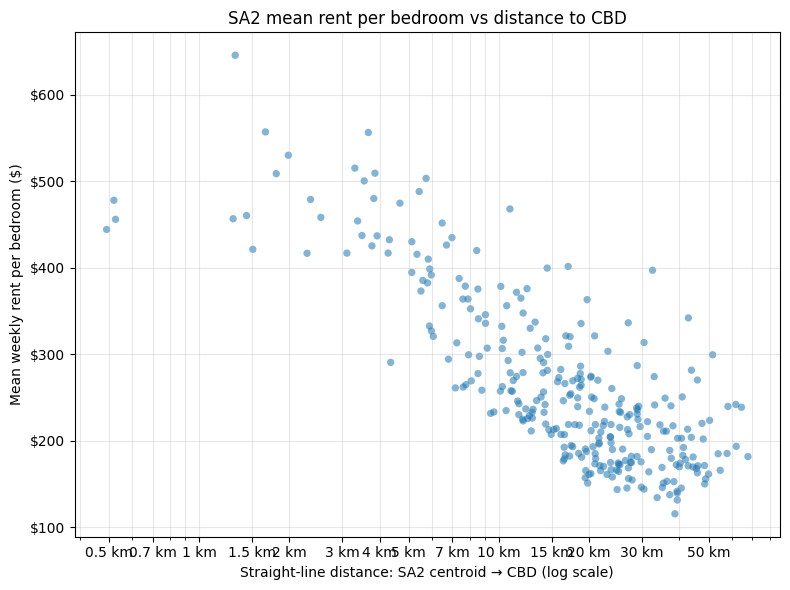

In [123]:
rentable = joined[
    joined["bedrooms"].gt(0) & joined["weekly_rent_number"].gt(0)
].copy()
rentable["rent_per_bedroom"] = rentable["weekly_rent_number"] / rentable["bedrooms"]

rent_by_sa2 = (
    rentable.groupby("SA2_NAME21")
    .agg(
        avg_rent_per_bedroom=("rent_per_bedroom", "mean"),
        n_rent_listings=("rent_per_bedroom", "size"),
    )
    .reset_index()
    .merge(sa2[["SA2_NAME21", "dist_cbd_km"]], on="SA2_NAME21", how="inner")
)
# Re-apply min-n on rentable counts (some eligible SA2s may lose listings after bed/rent filters)
rent_by_sa2 = rent_by_sa2[
    (rent_by_sa2["dist_cbd_km"] > 0) & (rent_by_sa2["n_rent_listings"] >= MIN_N)
].copy()

rent_by_sa2[["SA2_NAME21", "dist_cbd_km", "avg_rent_per_bedroom"]].to_csv(
    "transformed_data/rent_per_bedroom_vs_distance_to_cbd.csv", index=False
)
print(f"Rent SA2s retained (n_rent >= {MIN_N}): {len(rent_by_sa2):,}")

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(
    rent_by_sa2["dist_cbd_km"],
    rent_by_sa2["avg_rent_per_bedroom"],
    alpha=0.55,
    s=28,
    edgecolor="none",
)
ax.set_xscale("log")
xmin, xmax = rent_by_sa2["dist_cbd_km"].min(), rent_by_sa2["dist_cbd_km"].max()
ax.set_xticks(km_ticks(xmin, xmax))
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g} km"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"${y:,.0f}"))

ax.set_xlabel("Straight-line distance: SA2 centroid → CBD (log scale)")
ax.set_ylabel("Mean weekly rent per bedroom ($)")
ax.set_title("SA2 mean rent per bedroom vs distance to CBD")
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

### Fitting a model

Linear regression of mean rent per bedroom on log CBD distance (`rent ~ log(distance)`), matching the log-scaled x-axis above. `true_pct_above_mean` is how far the observed rent per bedroom sits above/below the predicted value for that SA2's CBD distance.

In [124]:
rent_fit_df = rent_by_sa2[["SA2_NAME21", "dist_cbd_km", "avg_rent_per_bedroom"]].dropna().copy()
X_rent = sm.add_constant(np.log(rent_fit_df["dist_cbd_km"]))
y_rent = rent_fit_df["avg_rent_per_bedroom"]

rent_fit = sm.OLS(y_rent, X_rent).fit()
print(rent_fit.summary())

                             OLS Regression Results                             
Dep. Variable:     avg_rent_per_bedroom   R-squared:                       0.652
Model:                              OLS   Adj. R-squared:                  0.650
Method:                   Least Squares   F-statistic:                     553.6
Date:                  Mon, 05 Oct 2026   Prob (F-statistic):           9.61e-70
Time:                          22:00:56   Log-Likelihood:                -1634.2
No. Observations:                   298   AIC:                             3272.
Df Residuals:                       296   BIC:                             3280.
Df Model:                             1                                         
Covariance Type:              nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const         520.9455     11.

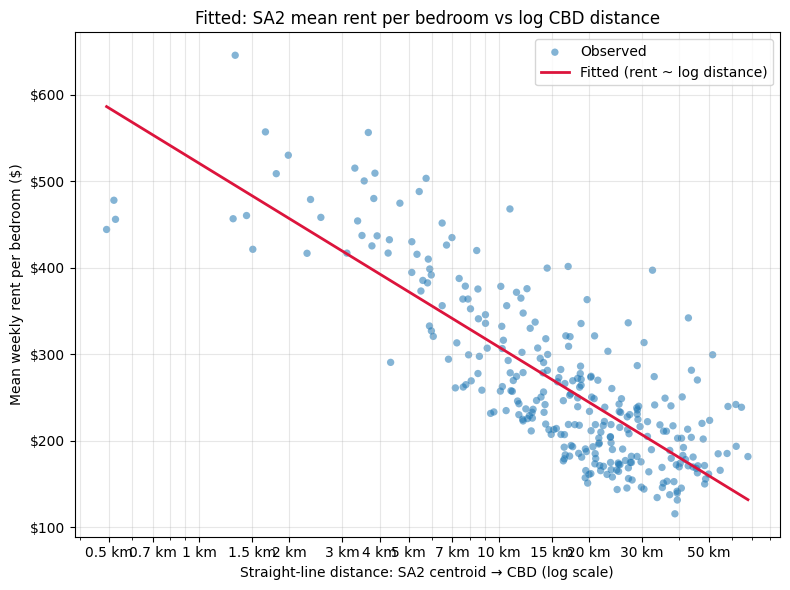

In [125]:
x_rent_line = np.logspace(
    np.log10(rent_fit_df["dist_cbd_km"].min()),
    np.log10(rent_fit_df["dist_cbd_km"].max()),
    200,
)
y_rent_line = rent_fit.predict(sm.add_constant(np.log(x_rent_line)))

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(
    rent_fit_df["dist_cbd_km"],
    rent_fit_df["avg_rent_per_bedroom"],
    alpha=0.55,
    s=28,
    edgecolor="none",
    label="Observed",
)
ax.plot(x_rent_line, y_rent_line, color="crimson", linewidth=2, label="Fitted (rent ~ log distance)")
ax.set_xscale("log")
xmin, xmax = rent_fit_df["dist_cbd_km"].min(), rent_fit_df["dist_cbd_km"].max()
ax.set_xticks(km_ticks(xmin, xmax))
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g} km"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"${y:,.0f}"))

ax.set_xlabel("Straight-line distance: SA2 centroid → CBD (log scale)")
ax.set_ylabel("Mean weekly rent per bedroom ($)")
ax.set_title("Fitted: SA2 mean rent per bedroom vs log CBD distance")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

In [126]:
rent_fit_df["predicted_rent_per_bedroom"] = rent_fit.predict(X_rent)
rent_fit_df["true_pct_above_mean"] = (
    (rent_fit_df["avg_rent_per_bedroom"] - rent_fit_df["predicted_rent_per_bedroom"])
    / rent_fit_df["predicted_rent_per_bedroom"]
)

rent_fit_df.head()

,SA2_NAME21,dist_cbd_km,avg_rent_per_bedroom,predicted_rent_per_bedroom,true_pct_above_mean
0,Abbotsford,3.380378,454.222222,408.549999,0.111791
1,Airport West,12.298999,236.969697,289.367997,-0.181078
2,Albert Park,3.555413,500.452381,403.891381,0.239077
3,Altona,14.028201,278.676471,277.228446,0.005223
4,Altona Meadows,17.412942,194.682540,257.282744,-0.243313


## Affordability–Amenity Access Tradeoff

Each SA2's residual from the two CBD-distance models: rent % above/below predicted (`true_pct_above_mean` from the rent fit) vs amenity distance % above/below predicted (from the amenity fit). Axes cross at the fitted expectation for that SA2's CBD distance.

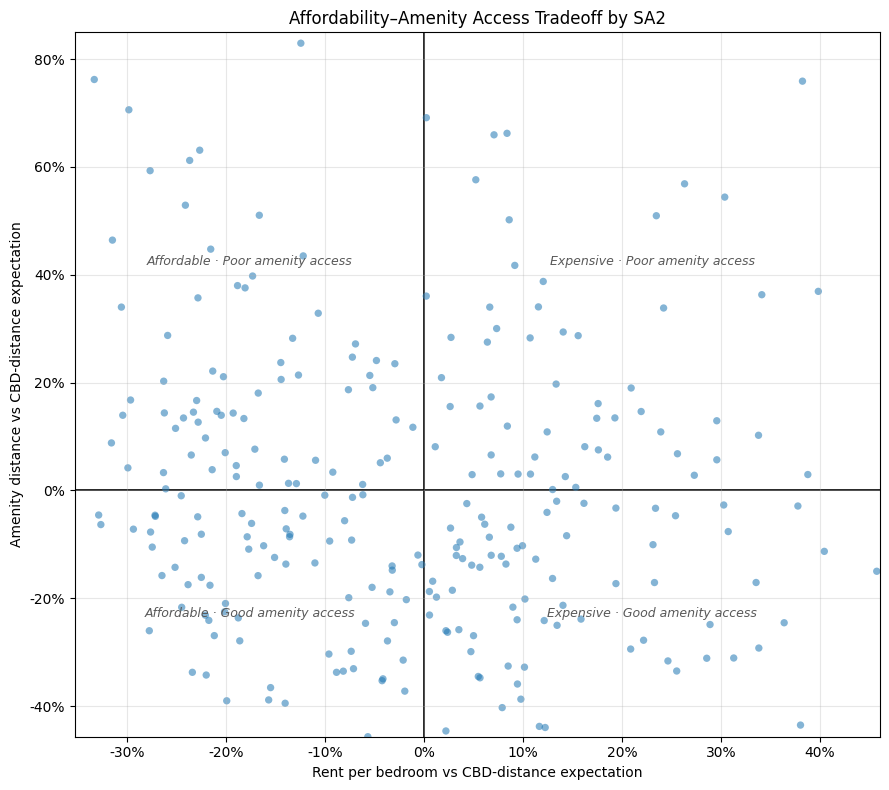

,SA2_NAME21,rent_pct_above_mean,amenity_pct_above_mean
0,Abbotsford,0.111791,0.061868
1,Airport West,-0.181078,0.375534
2,Albert Park,0.239077,0.108394
3,Altona,0.005223,-0.187633
4,Altona Meadows,-0.243313,0.134242


In [127]:
tradeoff = (
    rent_fit_df[["SA2_NAME21", "true_pct_above_mean"]]
    .rename(columns={"true_pct_above_mean": "rent_pct_above_mean"})
    .merge(
        fit_df[["SA2_NAME21", "true_pct_above_mean"]].rename(
            columns={"true_pct_above_mean": "amenity_pct_above_mean"}
        ),
        on="SA2_NAME21",
        how="inner",
    )
)

# Zoom to central mass (5th–95th percentile); extremes stay in the data but sit off-frame
x_lo, x_hi = tradeoff["rent_pct_above_mean"].quantile([0.05, 0.95])
y_lo, y_hi = tradeoff["amenity_pct_above_mean"].quantile([0.05, 0.95])
x_pad = 0.08 * (x_hi - x_lo)
y_pad = 0.08 * (y_hi - y_lo)
x_lo, x_hi = x_lo - x_pad, x_hi + x_pad
y_lo, y_hi = y_lo - y_pad, y_hi + y_pad

fig, ax = plt.subplots(figsize=(9, 8))
ax.scatter(
    tradeoff["rent_pct_above_mean"],
    tradeoff["amenity_pct_above_mean"],
    alpha=0.55,
    s=28,
    edgecolor="none",
)
ax.axhline(0, color="black", linewidth=1.2, zorder=0)
ax.axvline(0, color="black", linewidth=1.2, zorder=0)
ax.grid(True, alpha=0.3)
ax.set_xlim(x_lo, x_hi)
ax.set_ylim(y_lo, y_hi)

label_kw = dict(ha="center", va="center", fontsize=9, color="0.35", fontstyle="italic")
ax.text((x_lo + 0) / 2, (0 + y_hi) / 2, "Affordable · Poor amenity access", **label_kw)
ax.text((0 + x_hi) / 2, (0 + y_hi) / 2, "Expensive · Poor amenity access", **label_kw)
ax.text((x_lo + 0) / 2, (y_lo + 0) / 2, "Affordable · Good amenity access", **label_kw)
ax.text((0 + x_hi) / 2, (y_lo + 0) / 2, "Expensive · Good amenity access", **label_kw)

ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{100 * x:.0f}%"))
ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{100 * y:.0f}%"))
ax.set_xlabel("Rent per bedroom vs CBD-distance expectation")
ax.set_ylabel("Amenity distance vs CBD-distance expectation")
ax.set_title("Affordability–Amenity Access Tradeoff by SA2")
plt.tight_layout()
plt.show()

tradeoff.head()

### Interactive explorer

Hover any SA2 to see how its rent and amenity access compare to the CBD-distance expectation. Colour encodes a simple renter score (cheaper + closer amenities than expected → greener). Rings mark distance from the origin (fully "as expected"). Opens as a standalone HTML file.

In [128]:
import plotly.graph_objects as go

explorer = (
    tradeoff.merge(
        rent_by_sa2[["SA2_NAME21", "dist_cbd_km", "avg_rent_per_bedroom", "n_rent_listings"]],
        on="SA2_NAME21",
        how="inner",
    )
    .merge(
        fit_df[["SA2_NAME21", "avg_amenity_km", "predicted_amenity_dist"]],
        on="SA2_NAME21",
        how="inner",
    )
    .merge(
        rent_fit_df[["SA2_NAME21", "predicted_rent_per_bedroom"]],
        on="SA2_NAME21",
        how="inner",
    )
)

# Higher = better for a renter (cheaper than expected AND closer amenities than expected)
explorer["renter_score"] = -explorer["rent_pct_above_mean"] - explorer["amenity_pct_above_mean"]
explorer["residual_radius"] = np.sqrt(
    explorer["rent_pct_above_mean"] ** 2 + explorer["amenity_pct_above_mean"] ** 2
)

def _quadrant(row):
    cheap = row["rent_pct_above_mean"] < 0
    good_amenity = row["amenity_pct_above_mean"] < 0
    if cheap and good_amenity:
        return "Affordable · Good amenity access"
    if cheap and not good_amenity:
        return "Affordable · Poor amenity access"
    if (not cheap) and good_amenity:
        return "Expensive · Good amenity access"
    return "Expensive · Poor amenity access"

explorer["quadrant"] = explorer.apply(_quadrant, axis=1)

# Shared zoom with the static chart
x_lo, x_hi = tradeoff["rent_pct_above_mean"].quantile([0.05, 0.95])
y_lo, y_hi = tradeoff["amenity_pct_above_mean"].quantile([0.05, 0.95])
x_pad = 0.10 * (x_hi - x_lo)
y_pad = 0.10 * (y_hi - y_lo)
x_lo, x_hi = float(x_lo - x_pad), float(x_hi + x_pad)
y_lo, y_hi = float(y_lo - y_pad), float(y_hi + y_pad)

# Soft radial "cloud" underlay (closer to origin = more as-expected)
gx = np.linspace(x_lo, x_hi, 120)
gy = np.linspace(y_lo, y_hi, 120)
GX, GY = np.meshgrid(gx, gy)
# Normalise radius so rings read similarly on both axes
x_scale = max(abs(x_lo), abs(x_hi))
y_scale = max(abs(y_lo), abs(y_hi))
GZ = -np.sqrt((GX / x_scale) ** 2 + (GY / y_scale) ** 2)

fig = go.Figure()

fig.add_trace(
    go.Contour(
        x=gx,
        y=gy,
        z=GZ,
        colorscale=[
            [0.0, "rgba(232, 196, 168, 0.55)"],
            [0.45, "rgba(245, 240, 232, 0.35)"],
            [1.0, "rgba(168, 196, 176, 0.55)"],
        ],
        showscale=False,
        hoverinfo="skip",
        contours=dict(showlines=False, coloring="heatmap"),
        name="expectation cloud",
    )
)

# Concentric rings in normalised residual space
theta = np.linspace(0, 2 * np.pi, 180)
for r_norm, label in [(0.25, "close to expected"), (0.5, "moderate gap"), (0.75, "large gap")]:
    fig.add_trace(
        go.Scatter(
            x=r_norm * x_scale * np.cos(theta),
            y=r_norm * y_scale * np.sin(theta),
            mode="lines",
            line=dict(color="rgba(60, 64, 72, 0.22)", width=1.2, dash="dot"),
            hoverinfo="skip",
            showlegend=False,
            name=label,
        )
    )

hover_text = [
    (
        f"<b>{r.SA2_NAME21}</b><br>"
        f"<span style='color:#6b7280'>{r.quadrant}</span><br><br>"
        f"Rent vs expectation: <b>{100 * r.rent_pct_above_mean:+.0f}%</b>"
        f"  (${r.avg_rent_per_bedroom:,.0f}/bed · expect ${r.predicted_rent_per_bedroom:,.0f})<br>"
        f"Amenity distance vs expectation: <b>{100 * r.amenity_pct_above_mean:+.0f}%</b>"
        f"  ({r.avg_amenity_km:.2f} km · expect {r.predicted_amenity_dist:.2f} km)<br>"
        f"Distance to CBD: {r.dist_cbd_km:.1f} km<br>"
        f"Listings in sample: {int(r.n_rent_listings)}"
    )
    for r in explorer.itertuples()
]

fig.add_trace(
    go.Scatter(
        x=explorer["rent_pct_above_mean"],
        y=explorer["amenity_pct_above_mean"],
        mode="markers",
        marker=dict(
            size=10,
            color=explorer["renter_score"],
            colorscale=[
                [0.0, "#c47878"],
                [0.5, "#c4a574"],
                [1.0, "#5f8f7a"],
            ],
            cmid=0,
            opacity=0.88,
            line=dict(width=0.6, color="rgba(255,255,255,0.85)"),
            colorbar=dict(
                title=dict(text="Renter score<br><span style='font-size:11px'>(higher = better)</span>", side="right"),
                thickness=14,
                len=0.55,
                outlinewidth=0,
                bgcolor="rgba(255,255,255,0)",
                tickfont=dict(size=11, color="#5c6370"),
            ),
        ),
        text=hover_text,
        hoverinfo="text",
        name="SA2",
    )
)

# Axis cross at expectation
fig.add_hline(y=0, line=dict(color="rgba(40, 44, 52, 0.55)", width=1.4))
fig.add_vline(x=0, line=dict(color="rgba(40, 44, 52, 0.55)", width=1.4))

# Quiet quadrant cues
quad_notes = [
    (x_lo * 0.55, y_hi * 0.72, "Affordable · Poor access"),
    (x_hi * 0.55, y_hi * 0.72, "Expensive · Poor access"),
    (x_lo * 0.55, y_lo * 0.72, "Affordable · Good access"),
    (x_hi * 0.55, y_lo * 0.72, "Expensive · Good access"),
]
for x, y, label in quad_notes:
    fig.add_annotation(
        x=x,
        y=y,
        text=label,
        showarrow=False,
        font=dict(size=12, color="rgba(70, 76, 88, 0.45)", family="IBM Plex Sans, Helvetica Neue, sans-serif"),
    )

fig.update_layout(
    title=dict(
        text="Where to rent: affordability vs amenity access",
        font=dict(size=20, color="#2a2e36", family="IBM Plex Sans, Helvetica Neue, sans-serif"),
        x=0.02,
        xanchor="left",
    ),
    paper_bgcolor="#f4f1eb",
    plot_bgcolor="rgba(0,0,0,0)",
    font=dict(family="IBM Plex Sans, Helvetica Neue, sans-serif", color="#3a3f4b", size=13),
    margin=dict(l=70, r=90, t=70, b=60),
    width=980,
    height=780,
    hoverlabel=dict(
        bgcolor="rgba(250, 248, 244, 0.96)",
        bordercolor="rgba(60, 64, 72, 0.15)",
        font=dict(size=13, color="#2a2e36", family="IBM Plex Sans, Helvetica Neue, sans-serif"),
        align="left",
    ),
    xaxis=dict(
        title="Rent per bedroom vs CBD-distance expectation",
        range=[x_lo, x_hi],
        tickformat=".0%",
        zeroline=False,
        showgrid=True,
        gridcolor="rgba(60, 64, 72, 0.08)",
        gridwidth=1,
        linecolor="rgba(60, 64, 72, 0.25)",
    ),
    yaxis=dict(
        title="Amenity distance vs CBD-distance expectation",
        range=[y_lo, y_hi],
        tickformat=".0%",
        zeroline=False,
        showgrid=True,
        gridcolor="rgba(60, 64, 72, 0.08)",
        gridwidth=1,
        linecolor="rgba(60, 64, 72, 0.25)",
    ),
    showlegend=False,
)

out_path = Path("transformed_data") / "affordability_amenity_tradeoff.html"
out_path.parent.mkdir(parents=True, exist_ok=True)
fig.write_html(out_path, include_plotlyjs="cdn", full_html=True, config={"displayModeBar": False})
print(f"Wrote {out_path.resolve()}")

Wrote /Users/aditya/Library/CloudStorage/GoogleDrive-writetoadityay@gmail.com/Other computers/My Mac/MyMac_GoogleDrive/University/2026/Semester 2/MAST30034/real-estate-industry-project/modelling/liveability/transformed_data/affordability_amenity_tradeoff.html
